# Tutorial Notebook for IT_TF github repository

## Information Decay 
#### Starting from the ground up, we will generate 2 column MI/SI motifOrganisms encoding 2 bits of Total Information . We then bombard these motifs with mutations and compare how quickly their information decays (Note: Later, we switch to 0.5 bits of TI per position for computational tractability

First, let's generate the motifPopulation with SI (PI) organisms. All scripts in this repo are setup to work with parameters specified through json files. As such, we specify the parameters for the population before running the script which generates the desired motif Population

##### Note: In any/all scripts, SI from the paper is referred to as PI or IC in the code

In [3]:
import json

In [2]:
#Writing proper parameters for IC population to JSON file
ICjsonfile_fig1 = {
    "inputFile": None, #Loads in pre-generated motifPopulation or starts from scratch
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50, #Biases the mutation towards certain letters if not set to 0.50
	"Mutation_Rate": 0.01, #Expected rate of mutations per generation (mean of Poisson distribution)
	"MI_mode": 1, #Overlapping pairs (1) or non-overlapping pairs (2) for computing MI
	"ReadInFiles": None, #Paths to fasta files for initilaizing motifModels
	"Target_TI_Column": 1, #Target_TI_Column * Length_BindingSites equals desired bits of information
	"Prop_IC": 1, #Proportion of Target_TI_Column * Length_BindingSites that should be IC/PI
	"ConstrictMode": "IC", #Parameter of the fitness function. Determines whether to solely select for PI/IC, MI, or both
	"Eucledian_Thres": 0.05, #Max distance allowed for any organism from goal information before stopping simulation
    "restartPopulation": None, #If int specified, restarts population after # of generations. May help if getting stuck in local optima
	"populationOutputFile": "./Notebook/Populations/Figure_1/ICpop_fig1.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(ICjsonfile_fig1, f, indent = 3)



In [3]:
import src.fitMotifPopulation

version 0.1.8


In [4]:
#We then generate the ICmotifPop
src.fitMotifPopulation.main() 

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 0
Generation num: 400
Number Organisms below threshold: 0
Generation num: 500
Number Organisms below threshold: 0
Generation num: 600
Number Organisms below threshold: 0
Generation num: 700
Number Organisms below threshold: 0
Generation num: 800
Number Organisms below threshold: 0
Generation num: 900
Number Organisms below threshold: 0
Generation num: 1000
Number Organisms below threshold: 1
Generation num: 1100
Number Organisms below threshold: 10
Generation num: 1200
Number Organisms below threshold: 20
Generation num: 1300
Number Organisms below threshold: 44
Generation num: 1400
Number Organisms below threshold: 65
Generation num: 1500
Number Organisms below threshold: 86
Generation num: 1600
Number Organisms below threshold: 94
Generation num: 1700
Number Organisms below threshold: 

We then run the information decay experiment outlined in the paper, where we bombard our generated motifs with mutations in the absence of any selection pressure to see how fast the information decays

In [5]:
ICjsonfile_fig1_decay = {
    "Population_File":"./Notebook/Populations/Figure_1/ICpop_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": "./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.csv"	
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(ICjsonfile_fig1_decay, f, indent = 3)

In [6]:
import src.informationDecay

In [7]:
#We then run the Information Decay experiment
src.informationDecay.main()

Let's do the same with MI motifs. The only `parameters` changed are `Prop_IC`, `ConstrictMode`, and `restartPopulation` (Organisms above threshold will be removed and replaced with new random motifs after X generations to avoid local minimum)

In [8]:
#Writing proper parameters for MI population to JSON file
MIjsonfile_fig1 = {
    "inputFile": None,
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 1,
	"Prop_IC": 0,
	"ConstrictMode": "MI",
	"Eucledian_Thres": 0.05,
    "restartPopulation": 20000,
	"populationOutputFile": "./Notebook/Populations/Figure_1/MIpop_fig1.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(MIjsonfile_fig1, f, indent = 3)

In [9]:
#We then generate the MImotifPop
src.fitMotifPopulation.main() 

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 0
Generation num: 400
Number Organisms below threshold: 0
Generation num: 500
Number Organisms below threshold: 0
Generation num: 600
Number Organisms below threshold: 0
Generation num: 700
Number Organisms below threshold: 0
Generation num: 800
Number Organisms below threshold: 0
Generation num: 900
Number Organisms below threshold: 0
Generation num: 1000
Number Organisms below threshold: 0
Generation num: 1100
Number Organisms below threshold: 0
Generation num: 1200
Number Organisms below threshold: 0
Generation num: 1300
Number Organisms below threshold: 0
Generation num: 1400
Number Organisms below threshold: 0
Generation num: 1500
Number Organisms below threshold: 0
Generation num: 1600
Number Organisms below threshold: 0
Generation num: 1700
Number Organisms below threshold: 0
Gene

In [14]:
MIjsonfile_fig1_decay = {
    "Population_File":"./Notebook/Populations/Figure_1/MIpop_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": "./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.csv"		
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(MIjsonfile_fig1_decay, f, indent = 3)

In [15]:
#We then run the Information Decay experiment
src.informationDecay.main()

Here, we load in the csv files we produced from the decay experiments and report the instantaneous slope (the average number of bits of information loss by each population after the first mutation) 

In [16]:
import pandas as pd
PIdf = pd.read_csv("./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.csv")
MIdf = pd.read_csv("./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.csv")

#Instantenous slopes
PIslope = PIdf["IC"][0] - PIdf["IC"][1]
MIslope = MIdf["MI"][0] - MIdf["MI"][1]

print("PI lost after first mutation:", PIslope)
print("MI lost after first mutation:", MIslope)


PI lost after first mutation: 0.022048143864132674
MI lost after first mutation: 0.03994189134324411


Notice that the two slopes above come out to roughly a 2:3 ratio. In the paper, we analytically derive the information loss rate for two idealized ways a 2bp motif can spread its SI across its positions: all of it concentrated at a single position (Case A) or split evenly between both positions (Case B). Only Case B predicts a 2:3 ratio, which suggests the motifs we randomly sampled mostly resemble Case B rather than Case A. We can check this directly by computing the SI encoded at each position of every organism in the SI population we generated above

Figure(600x600)


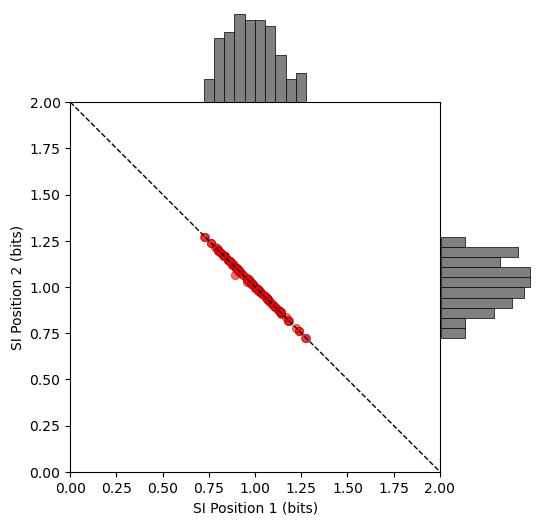

In [17]:
import src.figureFunctions

#Plots the PI at position 1 against the PI at position 2 for each organism, with the marginal distributions
print(src.figureFunctions.informationDistributionFig("./Notebook/Populations/Figure_1/ICpop_fig1.json"))

##### The points cluster around the middle of the diagonal, meaning our randomly sampled PI motifs overwhelmingly split their information close to evenly across the two positions (Case B). Motifs that concentrate their information at a single position (Case A) are comparatively rare, which is why the loss rate we measured above follows the Case B prediction

Visualizing the results. In figureFunctions.py, all the graphs from the paper and supplementary document can be regenerated given the results have already been generated

In [18]:
import src.figureFunctions


Figure(640x480)


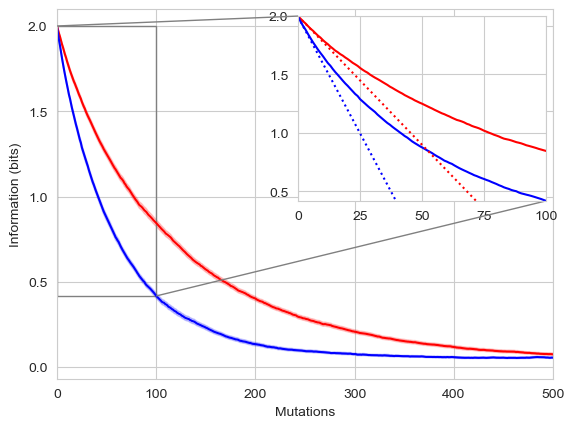

In [19]:
#Note: For the figure functions, order that we pass in the files is very important (Red is PI and blue is MI)
print(src.figureFunctions.informationDecayFig(["./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.csv",
                                               "./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.csv"]))

##### The above figure seems to indicate SI motifs maintain more of their Information after mutation than MI motifs. What about motifs between 100% SI and 100% MI? We proceed to generate motifs that encode their Information somewhere between 100% SI and 100% MI and compare their mutational resillience 

In [20]:
#Defines encoding strategies. 0% IC 100% MI, 25% IC 75% MI, ...
propInformation = [0,0.25,0.50, 0.75,1]

#Repeats the process completed above for each strata between 100% IC and 100% MI in propInformation
for percentageIC in propInformation:

    #Generates json file and outputs it
    mixedjsonfile_fig1 = {
    "inputFile": None,
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": percentageIC,
	"ConstrictMode": "",
	"Eucledian_Thres": 0.05,
    "restartPopulation": None,
	"populationOutputFile": f"./Notebook/Populations/SuppFigure_1/mixedpop_{percentageIC}_fig1.json"
    
    }  
    with open("./src/settings_fitMotifPop.json", "w") as f:
        json.dump(mixedjsonfile_fig1, f, indent = 3)

    #Generates population
    src.fitMotifPopulation.main() 

    #Runs information decay experiment
    mixedjsonfile_fig1_decay = {
    "Population_File":f"./Notebook/Populations/SuppFigure_1/mixedpop_{percentageIC}_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": f"./Notebook/Results/SuppFigure_1/informationDecay_mixedpop_{percentageIC}_fig1.csv"	
    }

    with open("./src/settings_informationDecay.json", "w") as f:
        json.dump(mixedjsonfile_fig1_decay, f, indent = 3)

    print(f"Done with {percentageIC}IC motifPopulation!") 
        
    src.informationDecay.main()

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 1
Generation num: 400
Number Organisms below threshold: 11
Generation num: 500
Number Organisms below threshold: 39
Generation num: 600
Number Organisms below threshold: 75
Generation num: 700
Number Organisms below threshold: 89
Generation num: 800
Number Organisms below threshold: 97
Generation num: 900
Number Organisms below threshold: 99
Generation num: 1000
Done with 0IC motifPopulation!
Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 3
Generation num: 400
Number Organisms below threshold: 14
Generation num: 500
Number Organisms below threshold: 50
Generation num: 600
Number Organisms below threshold: 86
Generation num: 700
Number 

Figure(640x480)


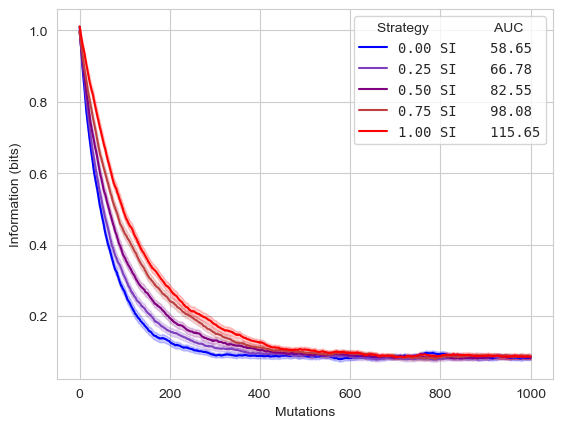

In [21]:
#Visualizing the results!
print(src.figureFunctions.mixedPopulationDecayFig([f"./Notebook/Results/SuppFigure_1/informationDecay_mixedpop_{percentageIC}_fig1.csv" for percentageIC in propInformation]))

##### The above figure seems to suggest that motifs that encode most of their information through PI are better positioned to maintain Information than motifs that trend more towards MI. We can see a clear improvement in mutational resilience going from MI to PI. 

##### A follow-up question. Transcription factors (TF) bind to sites that follow a certain motif pattern. Problems arise when these binding sites get mutated and start diverging from the pattern recognized by the TF. We can represent the original pattern as a probability frequency distribution and the mutated sites as another distribution. How does the divergence of IC binding sites from the motif after mutations compared to MI binding sites? To measure divergence, we employ Jennsen-Shannon Divergence

Figure(640x480)


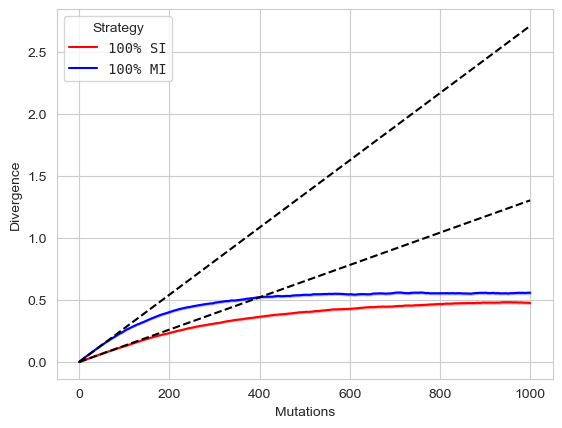

In [22]:
#Reusing the IC/MI informationDecay files we already generated, the JSD figure is visualized below
print(src.figureFunctions.divergenceFig(["./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.csv", 
                                         "./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.csv"]))

##### Examining whether these mutational resillience properties remain true of IC and MI motifs as we vary Information Density by altering `Target_TI_Column`

You could generate the populations yourself by setting `Target_TI_Column` to the following values: 0.25, 0.5, 0.75, and 1 bit for `Prop_IC` = 1 and `ConstrictMode` = IC as well for `Prop_IC`=0 and `ConstrictMode` = MI. This has already been done for you and saved to the repo. Here, we simply load in the pre-generated population 

In [23]:
#Defines different TI values for 2bp motif. 
TIlist = [0.5,1,1.5,2] 

#Repeats for MI and IC
for strategy in ["IC","MI"]:
    
    #Repeats the process completed above for each information density value in the list above
    for TI in TIlist:
        
        #Runs information decay experiment
        jsonfile_fig2_decay = {
        "Population_File":f"./Notebook/Populations/Figure_2/motifPop_{TI}bit{strategy}_2col.json",
    	"NumGenerationTerminate":1000,
    	"lossOutputCSV": f"./Notebook/Results/Figure_2/informationDecay_{TI}bit{strategy}.csv"	
        }
    
        with open("./src/settings_informationDecay.json", "w") as f:
            json.dump(jsonfile_fig2_decay, f, indent = 3)
                
        src.informationDecay.main()
    
    print(f"Done with {strategy} motifPopulations!") 


Done with IC motifPopulations!
Done with MI motifPopulations!


Figure(640x480)


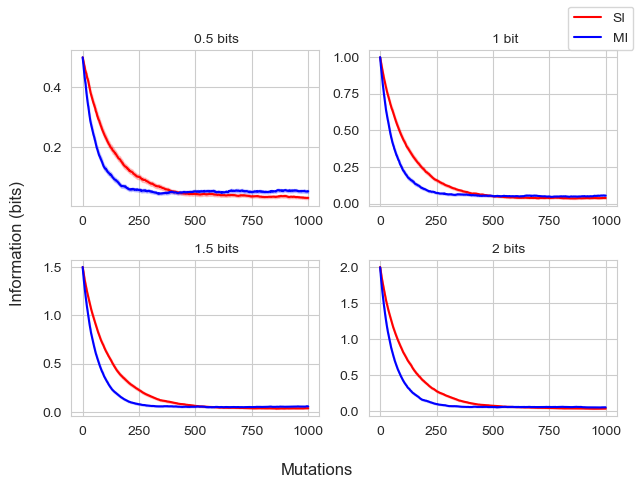

In [24]:
fig2_fileList = []
for TI in TIlist:
    fig2_fileList.append([f"./Notebook/Results/Figure_2/informationDecay_{TI}bitIC.csv",
                          f"./Notebook/Results/Figure_2/informationDecay_{TI}bitMI.csv" ])
fig2_fileList
print(src.figureFunctions.informationDecayByTIFig(fig2_fileList))

##### Finally, we generate more realistically sized motifs and repeat the information decay experiments 

You can generate these PI/MI MotifPopulations with `target_TI_Column`: 0.5 and `Length_BindingSites` = 12 selecting for PI/MI by altering `Prop_IC` to 1/0 and `ConstrictMode` to IC/MI. The generated populations are already saved and loaded in here:

In [25]:
#IC example (MI example takes much more time to generate)
ICjsonfile_fig3 = {
    "inputFile": None, 
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 12,
	"GC_cont": 0.50, 
	"Mutation_Rate": 0.01, 
	"MI_mode": 1, 
	"ReadInFiles": None, 
	"Target_TI_Column": 0.5, #Target_TI_Column * Length_BindingSites equals desired bits of information
	"Prop_IC": 1, #Adjust this to 0 for the MI population
	"ConstrictMode": "IC", #Adjust this to MI for the MI population
	"Eucledian_Thres": 0.05, 
    "restartPopulation": None, #If int specified, restarts population after # of generations. May help if getting stuck in local optima
	"populationOutputFile": "./Notebook/Populations/Figure_3/motifPop_6bitIC_12col.json" #Adjust this to not overwrite for MI population
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(ICjsonfile_fig3, f, indent = 3)

#We then generate the ICmotifPop
src.fitMotifPopulation.main() 


Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 0
Generation num: 400
Number Organisms below threshold: 0
Generation num: 500
Number Organisms below threshold: 0
Generation num: 600
Number Organisms below threshold: 0
Generation num: 700
Number Organisms below threshold: 0
Generation num: 800
Number Organisms below threshold: 0
Generation num: 900
Number Organisms below threshold: 0
Generation num: 1000
Number Organisms below threshold: 0
Generation num: 1100
Number Organisms below threshold: 0
Generation num: 1200
Number Organisms below threshold: 0
Generation num: 1300
Number Organisms below threshold: 0
Generation num: 1400
Number Organisms below threshold: 0
Generation num: 1500
Number Organisms below threshold: 0
Generation num: 1600
Number Organisms below threshold: 0
Generation num: 1700
Number Organisms below threshold: 0
Gene

KeyboardInterrupt: 

In [26]:
for strategy in ["IC", "MI"]:
    jsonfile_fig3_decay = {
        "Population_File":f"./Notebook/Populations/Figure_3/motifPop_6bit{strategy}_12col.json",
    	"NumGenerationTerminate":5000,
    	"lossOutputCSV": f"./Notebook/Results/Figure_3/informationDecay_{strategy}bit.csv"	
    }

    with open("./src/settings_informationDecay.json", "w") as f:
        json.dump(jsonfile_fig3_decay, f, indent = 3)
    
    #We then run the Information Decay experiment
    src.informationDecay.main()

Figure(640x480)


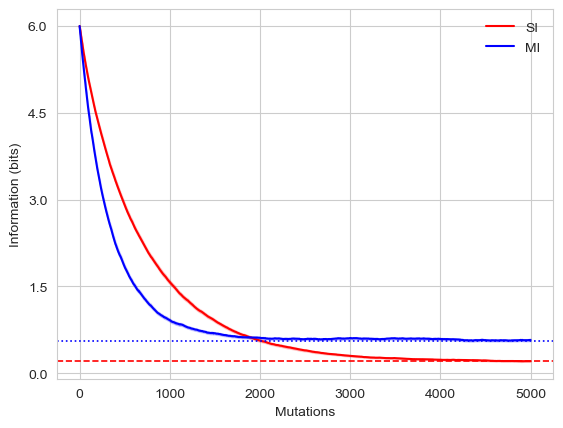

In [27]:
print(src.figureFunctions.residualInformationFig(["./Notebook/Results/Figure_3/informationDecay_ICbit.csv", "./Notebook/Results/Figure_3/informationDecay_MIbit.csv"])) 

# Genome Search
We now further complicate our model by introducing a genome to explore interesting properties about PI/MI motifs. Specifically, we insert our motifs into a genome, introduce mutations to the genome, and measure how quickly the classification ability of binding sites from non-binding sites degrade. We measure classification ability through AUPRC and train a Kulakovsky model on the binding sites before mutation to classify binding sites and non-binding sites.  

First, we load in our 6bp length fitted motifs. We apply the reduce residual information script so that both the PI and MI populations have the same amount of total information (if we did not do this, the AUPRC of both curves below would not start at the exact same place). We then run the genome search experiment by embedding the loaded motifs in randomly generated sequences (Code for doing so commented below. Too time-intensive to run in a notebook). We then measure AUPRC after mutation.


In [7]:
import src.genomeSearch
import src.main_removeResidual
import src.figureFunctions

Balance for residual information. This script accepts two populations and reduces the residual MI of the PI population s.t. both populations have equal Total Information. 


In [4]:
jsonfile_equalizeResidual = {
    "populationList":["./Notebook/Populations/Figure_3/motifPop_6bitMI_12col.json", "./Notebook/Populations/Figure_3/motifPop_6bitIC_12col.json"], #Input population paths. Order sensitive.  
    "MSE_thres":0.01
}

with open("./src/settings_residual.json", "w") as f:
    json.dump(jsonfile_equalizeResidual, f, indent = 3)

#Equalizes residual information and saves to same path
src.main_removeResidual.main()

0.18443922146410668
0.1751213487997285
0.1751213487997285
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.15136168604916536
0.

Note: This will take a *long* time if run in a jupyter notebook. As such, the results have already been generated by running the script and have been saved to Notebook/Results/Figure_4

In [5]:
run_code = False

if run_code:
    #Repeats for MI and IC
    for strategy in ["IC","MI"]:
        propIC = 1 if strategy == "IC" else 0
        #Repeats the process completed above for each motifLength above
        for L in motifLengths:
            inputMotifFilePath = f"./Notebook/Populations/Figure_3/motifPop_6bit{strategy}_12col.json"
            
            jsonfile_mainfig = {
            	"Population_File": inputMotifFilePath,
                "genomeLength": 8192, #Appropriate genome length according to Schneider's equation given 6 bits of information and 128 binding sites
                "NumGenerationTerminate": 10000, #Done in paper
                "lossOutputCSV": f"/Notebook/Results/Figure_4/genomeSearch_6bit{strategy}_12col.csv"
            }  
    
            with open("./src/settings_GenomeExperiment.json", "w") as f:
                json.dump(jsonfile_mainfig, f, indent = 3)
    
            #Runs genomeSearch
            src.genomeSearch.main() 


Figure(640x480)


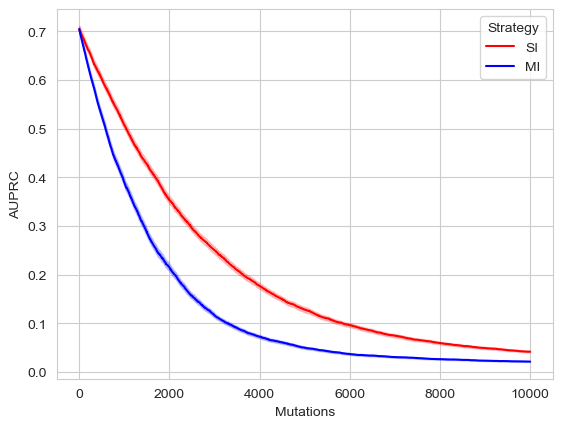

In [8]:
print(src.figureFunctions.genomeSearchFig(["./Notebook/Results/Figure_4/genomeSearch_6bitIC_12col.csv", "./Notebook/Results/Figure_4/genomeSearch_6bitMI_12col.csv"]))

# Coevolutionary Simulation
To further explore fitness properties of PI/MI TRNs, we use a coevolutionary simulation to evolve recognizers/binding sites along with the rest of the genome. We first tackle the question of whether MI or PI TRNs would propagate more in a population as a property of the higher mutational resillience of PI TRNs over MI TRNs (competition experiment). Given this mutational robustness property, we next ask whether TRNs would naturally move towards encoding their information through PI while solely selecting for classification performance (vector field). Please note that all of the below work was done with the assistance of a high performance computing cluster; however, the generated results are saved in the repo

Here, we demonstrate how the coevolutionary simulation functions by presenting the code necessary to generate the organisms for the competition experiment. To generate the PI vs MI organisms, we have to change `Percent_MI` parameter to 0.70 for MI organisms and 0.30 for PI organisms.

In [9]:
run_code = False

if run_code:
    #Repeats for MI and IC
    for strategy in ["IC","MI"]:
        propMI = 0.30 if strategy == "IC" else 0.70
        
        #More documentation available in script
        jsonfile_mainfig = {
            "Input_Files": None, #Input Files to seed coevolutionary simulation. Null starts from random
            "Number_Organisms": 2000,
            "Percent_MI": propMI, #What percentage MI to select for. percentage IC = 1 - percentageMI
            "Alpha": 1, #Weighting of Percent_MI in fitness function. Set to 0 to not consider percent_MI/IC at all
            "AUPRC":1, #What AUPRC to fit towards
            "Beta": 100, #Base of exponent in fitness population
            "Genome_Length": 2048,
            "Number_BindingSites_Recognizer": 32,
            "Length_BindingSites": 6,
            "Number_BindingSites": 32,
            "Stopping_Criteria": None, #Stopping criteria. Set to null to stop when top organism is at 1AUPRC 
            "Error_Threshold": 0.02, #Only relevent when Stopping_criteria = fitness. Used in preparing vector field experiment
            "Grid_Threshold": 0.10, #Only relevent when Stopping_criteria = grid. Used in conducting vector field experiment
            "idList": None, #Only relevent when running the competition experiment
            "run_mode":"parallel", 
            "Output_Folder":f"/Users/Emmanuel/Documents/Research Projects/ITTF/Output/Generate{strategy}Orgs/", #Saves below files to this path
            "Output_CSV_FileName": f"runCompetition.csv", #Outputs statistics of simulation
            "Output_Diversity_FileName":"diversity.csv",
            "Output_topAUPRC_Org_FileName": "MIorg_topAUPRC.json", #Outputs top AUPRC organism
            "Output_topFitness_Org_FileName": "MIorg_topFitness.json", #Outputs top fitness organism
            "Output_Pop_FileName": "MIpop.json" #Outputs population file
            }  
    
        with open("./src/settings_fitCoevPop.json", "w") as f:
            json.dump(jsonfile_mainfig, f, indent = 3)
    
        #Generates organism
        src.fitCoevPopulation.main() 


Note, for the competition experiment, we generated 25 PI and MI organisms using the above code in a high performance computing cluster. We then generated 100 pairings with replacement (saved in `Output/competitionPairs/`). The code below demonstrates what would need to be done to run the competition experiment (we would need to repeat this process for all 100 pairs). Results are saved in `Output/resultsCompetition`. 

To run the competition experiment, we have to change `Input_Files` to start the simulation from our pre-generated organisms, `Alpha` since we are no longer selecting for %MI/PI, `Stopping_Criteria` as we stop the simulation when all organisms in the population come from one parent organism, and `idList` to give each parent organism an id (i.e. MI_70 for the MI organism)

In [10]:
run_mode = False

if run_mode:
    #More documentation available in script
    jsonfile_mainfig = {
        "Input_Files": ["./Output/competitionPairs/competitionpair_0/MIorg.json","./Output/competitionPairs/competitionpair_0/ICorg.json"], #Initializes population by duplicating the organisms stored in these two file paths 
        "Number_Organisms": 2000,
        "Percent_MI": 0.30, 
        "Alpha": 0, #Solely selects for AUPRC
        "AUPRC":1, 
        "Beta": 100, 
        "Genome_Length": 2048,
        "Number_BindingSites_Recognizer": 32,
        "Length_BindingSites": 6,
        "Number_BindingSites": 32,
        "Stopping_Criteria": "competition", #Stops when one organism out-competes the other (when all organisms in the population come from one of the two above organisms)
        "Error_Threshold": 0.02, #Only relevent when Stopping_criteria = fitness. Used in preparing vector field experiment
        "Grid_Threshold": 0.10, #Only relevent when Stopping_criteria = grid. Used in conducting vector field experiment
        "idList": ["MI_70","MI_30"], #ID tags of two parent organisms. 
        "run_mode":"parallel", 
        "Output_Folder":f"/Users/Emmanuel/Documents/Research Projects/ITTF/Output/resultsCompetition/competitionpair_0/", #Saves below files to this path
        "Output_CSV_FileName": f"/Users/Emmanuel/Documents/Research Projects/ITTF/Output/resultsCompetition/competitionpair_0/runCompetition.csv", #Saves to absolute path
        "Output_Diversity_FileName":"diversity.csv",
        "Output_topAUPRC_Org_FileName": "MIorg_topAUPRC.json", #Outputs top AUPRC organism
        "Output_topFitness_Org_FileName": "MIorg_topFitness.json", #Outputs top fitness organism
        "Output_Pop_FileName": "MIpop.json" #Outputs population file
        }  
    
    with open("./src/settings_fitCoevPop.json", "w") as f:
        json.dump(jsonfile_mainfig, f, indent = 3)
    
    #Generates organism
    src.fitCoevPopulation.main() 


     Generation  MI_70 org frequency  MI_30 org frequency
0             0               0.5000               0.5000
1             1               0.4915               0.5085
2             2               0.4780               0.5220
3             3               0.4780               0.5220
4             4               0.4780               0.5220
..          ...                  ...                  ...
995         280               0.0000               1.0000
996         280               0.0000               1.0000
997         280               0.0000               1.0000
998         280               0.0000               1.0000
999         280               0.0000               1.0000

[1000 rows x 3 columns]
Figure(640x480)


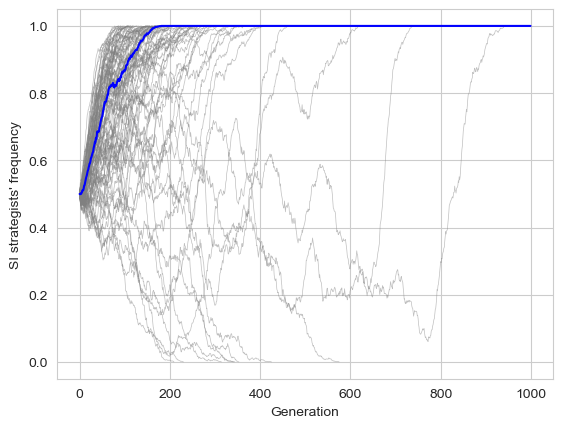

In [11]:
#Plots figure from saved results
print(src.figureFunctions.competitionFig())

Given that PI TRNs outcompete MI TRNs, we now ask whether a freely evolving TRN would move towards PI on its own while we solely select for classification performance. To do this, we discretize the phenotype space of our TRNs into a grid of 25 cells (5 bins of AUPRC by 5 bins of percent PI) and estimate the expected evolutionary change in each cell. Each cell takes three steps. First, we evolve a seed organism that sits at the center of the cell, second we clone that organism into a population and let it evolve under AUPRC selection alone until the population's centroid crosses the cell boundary, and third we record the displacement from start to finish. We repeat this 10 times per cell and average the displacements into the arrow plotted for that cell. As with the competition experiment, all of this was run on a high performance computing cluster and the generated results are saved in `Output/gridResults/`

First, we generate the seed organism sitting at the center of each cell. Here we select for both %MI and AUPRC (`Alpha` = 1) and set `Stopping_Criteria` to fitness, which stops the simulation as soon as the top organism gets within `Error_Threshold` of the cell center

In [12]:
#Phase space is discretized into a 5x5 grid. The values below are the cell centers
AUPRCbins = [0.1,0.3,0.5,0.7,0.9]
MIbins = [0.1,0.3,0.5,0.7,0.9]

run_code = False

if run_code:
    #Generates 10 seed organisms at the center of each of the 25 cells (one per replica)
    for targetAUPRC in AUPRCbins:
        for targetMI in MIbins:
            for replica in range(10):
                
                #More documentation available in script
                jsonfile_gridseed = {
                    "Input_Files": None, #Starts the simulation from a randomly initialized population
                    "Number_Organisms": 2000,
                    "Percent_MI": targetMI, #Targets the %MI at the center of this cell
                    "Alpha": 1, #Weights %MI the same as AUPRC so the organism lands on the cell center
                    "AUPRC": targetAUPRC, #Targets the AUPRC at the center of this cell
                    "Beta": 100, 
                    "Genome_Length": 2048,
                    "Number_BindingSites_Recognizer": 32,
                    "Length_BindingSites": 6,
                    "Number_BindingSites": 32,
                    "Stopping_Criteria": "fitness", #Stops once the top organism is close enough to the cell center
                    "Error_Threshold": 0.01, #Max eucledian distance from the cell center before stopping
                    "Grid_Threshold": 0.10, #Not used here. Relevent in the next cell
                    "idList": None, 
                    "run_mode":"parallel", 
                    "Output_Folder": f"./Output/gridOrganisms/{targetAUPRC}AUPRC/{targetMI}MI/", #Saves below files to this path
                    "Output_CSV_FileName": "MIorg.csv", #Outputs statistics of simulation
                    "Output_Diversity_FileName":"diversity.csv",
                    "Output_topAUPRC_Org_FileName": "MIorg_topAUPRC.json",
                    "Output_topFitness_Org_FileName": "MIorg_topFitness.json", #This is the seed organism for this replica
                    "Output_Pop_FileName": "MIpop.json" #Outputs population file
                    }  
        
                with open("./src/settings_fitCoevPop.json", "w") as f:
                    json.dump(jsonfile_gridseed, f, indent = 3)
        
                #Generates one seed organism for this cell
                src.fitCoevPopulation.main() 


We then clone each seed organism into a fresh population and let it evolve. We have to change `Input_Files` to start the simulation from the seed organism we just generated, `Alpha` since we are no longer selecting for %MI, and `Stopping_Criteria` to grid, which stops the simulation once the population's centroid moves `Grid_Threshold` away from the cell center (i.e. reaches the cell boundary). The collected seeds are already saved in the repo under `Output/gridOrganisms/`

In [13]:
import os

run_code = False

if run_code:
    for targetAUPRC in AUPRCbins:
        for targetMI in MIbins:
            
            #10 independent replicas per cell. These get averaged into the one arrow drawn for the cell
            for replica in range(10):
                
                #vectorField() reads the csvs from this path, so we pass it as an absolute path
                outputCSV = os.path.abspath(f"./Output/gridResults/{targetAUPRC}AUPRC/{targetMI}MI/MIorg_{replica}.csv")
                
                #More documentation available in script
                jsonfile_grid = {
                    "Input_Files": [f"./Output/gridOrganisms/{targetAUPRC}AUPRC/{targetMI}MI/MIorg_topFitness_{replica}.json"], #Initializes population by duplicating this replica's seed organism
                    "Number_Organisms": 2000,
                    "Percent_MI": targetMI, 
                    "Alpha": 0, #Solely selects for AUPRC
                    "AUPRC": 1, 
                    "Beta": 100, 
                    "Genome_Length": 2048,
                    "Number_BindingSites_Recognizer": 32,
                    "Length_BindingSites": 6,
                    "Number_BindingSites": 32,
                    "Stopping_Criteria": "grid", #Stops once the population centroid reaches the boundary of the cell
                    "Error_Threshold": 0.01, 
                    "Grid_Threshold": 0.10, #Distance from the center of the cell to its boundary
                    "idList": None, 
                    "run_mode":"parallel", 
                    "Output_Folder": f"./Output/gridResults/{targetAUPRC}AUPRC/{targetMI}MI/", #Saves below files to this path
                    "Output_CSV_FileName": outputCSV, #Saves to absolute path
                    "Output_Diversity_FileName":"diversity.csv",
                    "Output_topAUPRC_Org_FileName": "MIorg_topAUPRC.json",
                    "Output_topFitness_Org_FileName": "MIorg_topFitness.json",
                    "Output_Pop_FileName": "MIpop.json" #Outputs population file
                    }  
        
                with open("./src/settings_fitCoevPop.json", "w") as f:
                    json.dump(jsonfile_grid, f, indent = 3)
        
                #Runs one replica of the grid experiment for this cell
                src.fitCoevPopulation.main() 


Finally, the two points (*mutational steady state* and *selection steady state*) plotted on the figure. Both come from the seed populations of a single cell, except we let the simulation run for a fixed number of generations instead of stopping at the cell boundary (`Stopping_Criteria` accepts an int for this). The star is the steady state under selection, which we get by rerunning the seed populations from the (70% PI, 0.9 AUPRC) cell for 27,000 generations. The cross is the steady state in the absence of selection, which we get by rerunning the seed populations from the (30% PI, 0.1 AUPRC) cell for 10,000 generations

In [14]:
run_code = False

if run_code:
    #Star is the steady state under selection. Cross is the steady state without selection
    steadyStates = [{"cell": (0.9, 0.3), "generations": 27000, "outputFolder": "./Output/gridEquilibrium/0.3MI/"},
                    {"cell": (0.1, 0.7),  "generations": 10000, "outputFolder": "./Output/gridEquilibrium/0.7MI/"}]
    
    for steadyState in steadyStates:
        targetAUPRC, targetMI = steadyState["cell"]
        
        #Reuses the same 10 seed organisms we used for this cell in the grid experiment above
        for replica in range(10):
            
            outputCSV = os.path.abspath(f"{steadyState['outputFolder']}MIorg_{replica}.csv")
            
            #More documentation available in script
            jsonfile_equilibrium = {
                "Input_Files": [f"./Output/gridOrganisms/{targetAUPRC}AUPRC/{targetMI}MI/MIorg_topFitness_{replica}.json"], 
                "Number_Organisms": 2000,
                "Percent_MI": targetMI, 
                "Alpha": 0, #Solely selects for AUPRC
                "AUPRC": 1, 
                "Beta": 100,
                "Genome_Length": 2048,
                "Number_BindingSites_Recognizer": 32,
                "Length_BindingSites": 6,
                "Number_BindingSites": 32,
                "Stopping_Criteria": steadyState["generations"], #Runs for this many generations, ignoring the cell boundaries
                "Error_Threshold": 0.01, 
                "Grid_Threshold": 0.10, 
                "idList": None, 
                "run_mode":"parallel", 
                "Output_Folder": steadyState["outputFolder"], #Saves below files to this path
                "Output_CSV_FileName": outputCSV, #Saves to absolute path
                "Output_Diversity_FileName":"diversity.csv",
                "Output_topAUPRC_Org_FileName": "MIorg_topAUPRC.json",
                "Output_topFitness_Org_FileName": "MIorg_topFitness.json",
                "Output_Pop_FileName": "MIpop.json" #Outputs population file
                }  
    
            with open("./src/settings_fitCoevPop.json", "w") as f:
                json.dump(jsonfile_equilibrium, f, indent = 3)
    
            #Runs one replica of the steady state experiment
            src.fitCoevPopulation.main() 


start coordinates:  (26.512570562688435, 0.016935527215320878)
end coordinates:  (75.92638228212209, 0.9398650684835652)
Figure(640x480)


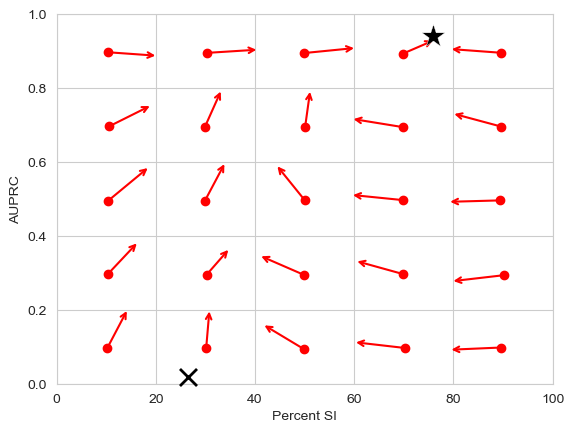

In [15]:
#Plots figure from saved results. Also prints the coordinates of the cross and the star
#Pass verbose=True to also print the start and end coordinates of every cell in the grid
print(src.figureFunctions.vectorField())

The vector field tells us where a freely evolving TRN ends up, but not how surprising those endpoints are. Since the space of motifs that encode their information through MI is much larger than the space of motifs that rely on PI, we should expect a randomly drawn motif to be MI heavy simply because there are more ways for it to be MI heavy. To measure this representational bias, we uniformly sample 6 column motifs at each value of total information (TI) and record how percent PI is distributed. The star and the cross from the vector field are then mapped onto that distribution, using the same coordinates the cell above printed

Figure(550x400)


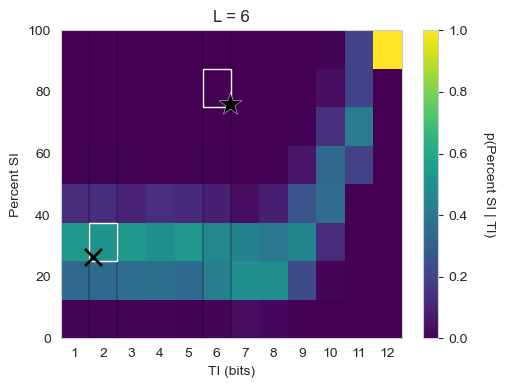

In [16]:
#Samples 1000 motifs per TI value, so this cell takes a moment to run
print(src.figureFunctions.percentSIheatmapFig())

##### The cross lands in the highest density region of the distribution, which confirms that the steady state in the absence of selection is simply where random sampling puts a motif. The star instead lands in a low density region, so the PI rich attractor we found under selection is not likely under random chance. 

We can repeat this sampling across motif lengths to check that the bias is not specific to the 6 column motifs we have been working with. Here we also stop approximating the correlations with the MI between adjacent positions and use the total correlation C instead (`only_adj_MI` = False), which accounts for non adjacent and higher order correlations as well. On the L = 3 panel we mark the standard genetic code with a red diamond, which we come back to below

Generating data for L=2 ...
Generating data for L=3 ...
Generating data for L=4 ...
Generating data for L=5 ...
Generating data for L=6 ...
Generating data for L=7 ...
Generating data for L=8 ...
Figure(1400x700)


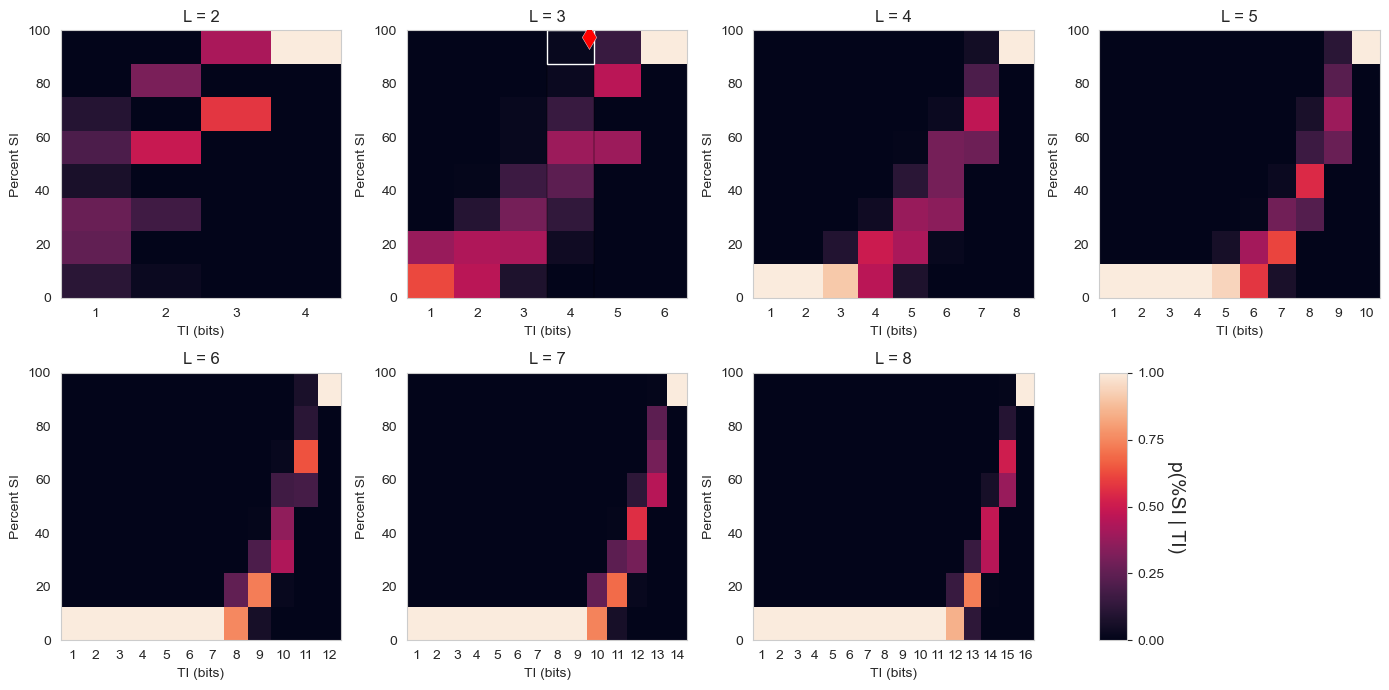

In [17]:
#Sweeps L from 2 to 8 bp, sampling 1000 motifs per TI value as in the paper. This takes a couple
#of minutes, so uncomment the line below it for a faster but noisier version of the figure
#print(src.figureFunctions.percentSIsweepFig(sample_size = 1000))
print(src.figureFunctions.percentSIsweepFig(sample_size = 100))

##### The same pattern holds at every motif length. PI rich motifs stay rare until TI approaches the maximum information the motif can carry, and the red diamond shows that the standard genetic code sits far above what random sampling of 3 column motifs would give us

# Genotype-Phenotype Map
Mutational robustness is not the only property we care about. A motif also has to be able to move through sequence space to tune its binding, so we now characterize the TF-DNA binding affinity landscape of motifs across encoding strategies. We describe each landscape with three metrics: the fitness distance correlation (FDC), where affinity takes the place of fitness, the genotype distance to phenotype distance correlation (GDPDC), and the number of optima in the landscape. We do this for the same five strategies we used earlier, from 0% PI (100% MI) up to 100% PI (0% MI), with 100 sampled motifs per strategy

The motifs are already saved in the repo under `data/MI_to_PI_2bp_Motifs` and `data/MI_to_PI_6bp_Motifs`. The analysis below walks the entire genotype space of each motif, so this will take a *long* time if run in a jupyter notebook. As such, the results have already been generated and saved to `Output/GPM`

In [18]:
import src.make_fig_5B

run_code = False

if run_code:
    #Repeats the landscape analysis for 2 and 6 column motifs
    for motifLength in [2,6]:
        src.make_fig_5B.run_gpm_analysis(motif_length = motifLength,
                                         motifs_base_dirpath = f"./data/MI_to_PI_{motifLength}bp_Motifs",
                                         results_dirpath = f"./Output/GPM/{motifLength}bp_motifs/")

TypeError: boxplot() got an unexpected keyword argument 'tick_labels'

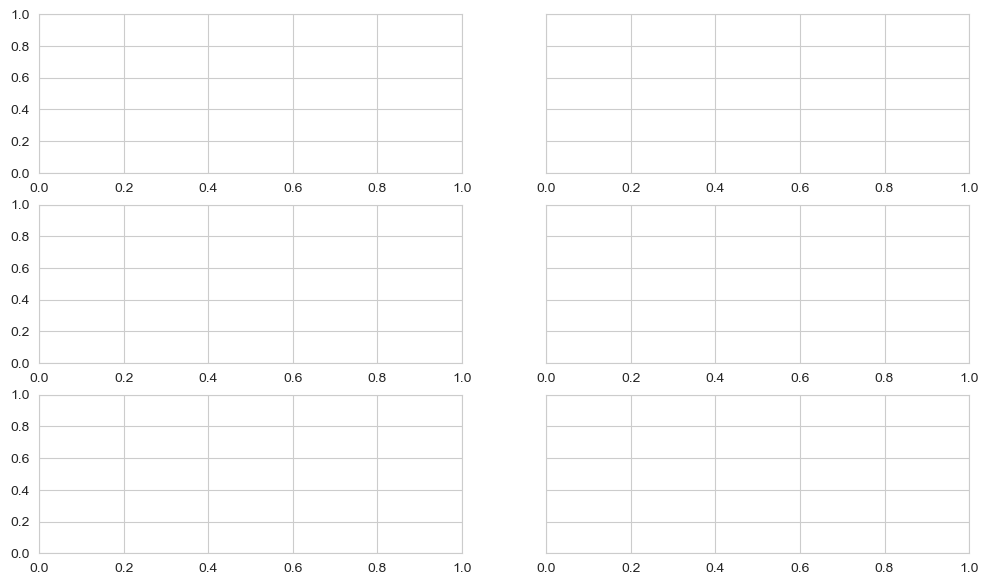

In [19]:
#Plots figure from saved results
print(src.figureFunctions.gpmAnalysisFig())

##### FDC and GDPDC both climb as motifs shift from MI to PI, meaning the affinity landscape of a PI motif is more correlated and therefore easier to navigate by mutation. The number of optima falls over the same range, so PI motifs also present fewer local peaks to get stuck on. Taken with the robustness results above, this tells us that PI does not buy robustness at the cost of evolvability

# The Genetic Code
If encoding information through PI really does grant mutational robustness, the advantage should not be specific just to transcriptional regulation. The genetic code gives us a second and  better characterized code to check this on. We can treat it as 21 sequence motifs, one per message, where each of the 20 amino acids and the stop signal is encoded by a set of synonymous codons. Below we compute the percent PI of the standard code together with its mutational robustness, measured as the probability of still incorporating the correct amino acid after a random point mutation, and compare both against 1000 randomized codes that preserve the degeneracy of the standard code while permuting which codons map to which message

In [20]:
#Randomizes 1000 codes as in the paper, reporting progress every 100 codes. This takes a few
#minutes, so uncomment the line below it for a faster version with fewer random codes
print(src.figureFunctions.geneticCodeRobustnessFig(n_random = 1000))
#print(src.figureFunctions.geneticCodeRobustnessFig(n_random = 100))

ModuleNotFoundError: No module named 'logomaker'

##### The standard genetic code (red diamond) separates from the random codes on both axes, and the two axes are strongly correlated, which is the relationship we predicted. Read alongside the L = 3 panel of the sweep above, the percent PI of the standard code is not only high relative to other codes, it is high relative to 3 column motifs in general

To see where that percent PI comes from, we can draw each message as a sequence logo. We add one extra bar to every logo reporting the total correlation C in bits, so that the information encoded through correlations between codon positions sits next to the information encoded at each position on its own. We plot the standard code alongside a randomized code for comparison

In [21]:
#Returns two figures, the standard code first and a randomized code second
standardCodeFig, randomCodeFig = src.figureFunctions.geneticCodeLogosFig()

ModuleNotFoundError: No module named 'logomaker'

##### Nearly every message in the standard code has a correlation bar at or near zero, so the code encodes its information position by position. The randomized code instead puts a substantial amount of information into correlations for most of its messages. The four messages in the standard code that do carry correlations are worth a closer look

Since a codon is only three positions long, we can draw the genotype space of each message in full. Every codon is one cell of a 4x4x4 cube, with one axis per codon position, and we highlight the cells belonging to the message. Maeshiro and Kimura noted that viewed this way each message occupies a regular subset of the cube that follows specific geometric constraints, with four exceptions. Those four exceptions are boxed below

In [ ]:
#Pairs each sequence logo with the genotype table of that message, drawn as a cube
print(src.figureFunctions.geneticCodeCubesFig())

##### The four boxed messages are exactly the ones whose correlation bar is greater than zero. The geometric irregularity Maeshiro and Kimura identified and the presence of correlations between codon positions are therefore the same observation, which is what we would expect given that a message can only avoid correlations if its codons form a regular subset of the cube